# Used Airplane Prices

What makes a small used airplane expensive? The data joins three tables (sales, specifications and performance) for 195 aircraft.

The plots use the original units. For modelling, `clean()` in `src/airplane/preprocessing.py` also takes the log of horsepower, fuel, ceiling and cruise speed.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from src.airplane.data_ingestion import DataIngestion

sns.set_theme(style="white", palette="Set2", rc={"axes.spines.top": False, "axes.spines.right": False})

planes = DataIngestion().load_all().drop(columns="0Sale_ID")
display(planes.head())

,age,price,pass,wtop,fixgear,tdrag,horse,fuel,ceiling,cruise
0,22,9000,2,0,0,0,112,30,8500,108
1,21,10000,2,0,0,0,112,30,8500,108
2,20,11500,2,0,0,0,112,30,8500,108
3,19,13000,2,0,0,0,112,30,8500,111
4,22,17000,2,1,0,0,110,39,8500,107


| Column | Meaning |
|---|---|
| `price` | Sale price, dollars |
| `age` | Age, years |
| `pass` | Passenger seats |
| `wtop` | 1 = high wing, 0 = low wing |
| `fixgear` | Landing gear indicator (0/1) |
| `tdrag` | 1 = tail-dragger, 0 = nose wheel |
| `horse` | Engine horsepower |
| `fuel` | Fuel capacity |
| `ceiling` | Maximum altitude, feet |
| `cruise` | Cruising speed |

## Summary statistics

In [2]:
display(planes.describe().T.round(1))

,count,mean,std,min,25%,50%,75%,max
age,195.0,24.6,7.0,13.0,19.0,22.0,30.0,44.0
price,195.0,50236.7,41470.3,9000.0,19250.0,33500.0,73500.0,254000.0
pass,195.0,4.3,1.3,2.0,4.0,4.0,6.0,6.0
wtop,195.0,0.5,0.5,0.0,0.0,0.0,1.0,1.0
fixgear,195.0,0.5,0.5,0.0,0.0,0.0,1.0,1.0
tdrag,195.0,0.1,0.2,0.0,0.0,0.0,0.0,1.0
horse,195.0,219.2,60.5,108.0,180.0,210.0,285.0,310.0
fuel,195.0,67.8,20.3,29.0,51.0,68.0,84.0,130.0
ceiling,195.0,14006.7,4503.2,8500.0,9700.0,13000.0,16800.0,28000.0
cruise,195.0,144.7,31.3,97.0,119.0,144.0,170.0,221.0


## Sale prices

Most planes sold for under $50,000, with a long tail of pricier aircraft. The dashed line marks the median.

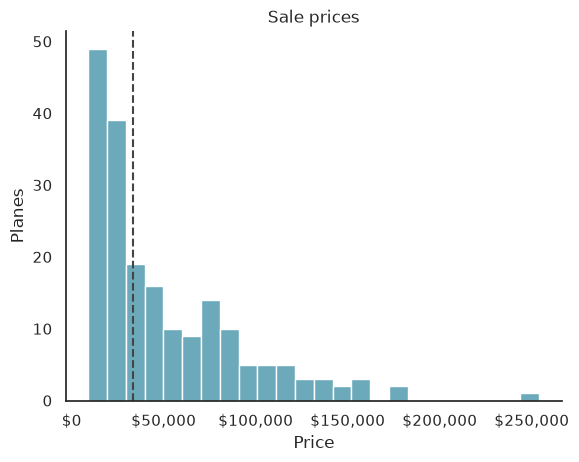

In [3]:
ax = sns.histplot(data=planes, x="price", binwidth=10_000, color="#3B8EA5")
ax.axvline(planes["price"].median(), linestyle="--", color="#444444")
ax.xaxis.set_major_formatter("${x:,.0f}")
ax.set(title="Sale prices", xlabel="Price", ylabel="Planes")
plt.show()

## What moves with price?

The correlation of each feature with price.

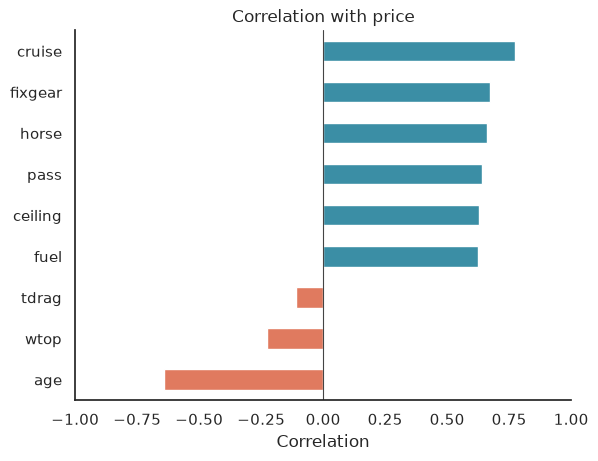

In [4]:
correlations = planes.corr()["price"].drop("price").sort_values()

ax = correlations.plot.barh(color=["#E07A5F" if value < 0 else "#3B8EA5" for value in correlations])
ax.axvline(0, color="#444444", linewidth=0.8)
ax.set(title="Correlation with price", xlabel="Correlation", xlim=(-1, 1))
plt.show()

## Speed, age and price

Each dot is one plane: its cruising speed against its price, coloured by age. Faster planes sell for more, and the darkest (oldest) planes sit lowest.

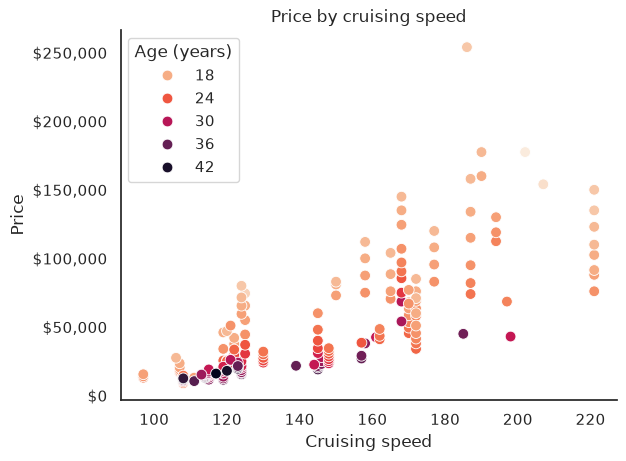

In [5]:
ax = sns.scatterplot(data=planes, x="cruise", y="price", hue="age", palette="rocket_r", s=60)
ax.legend(title="Age (years)")
ax.yaxis.set_major_formatter("${x:,.0f}")
ax.set(title="Price by cruising speed", xlabel="Cruising speed", ylabel="Price")
plt.show()

## Passenger seats

The spread of prices for 2-, 4- and 6-seat planes; the line in each box is the median.

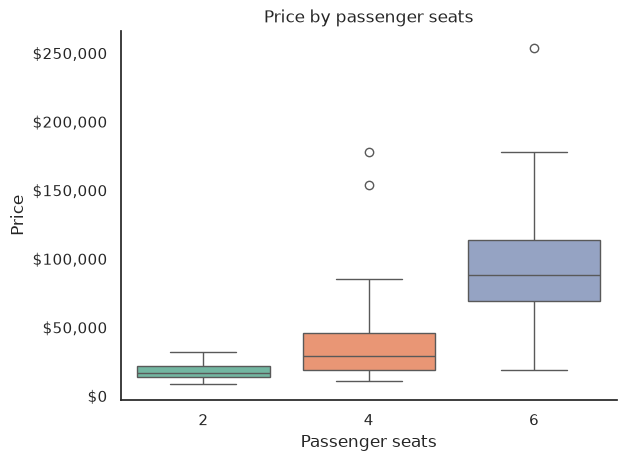

In [6]:
ax = sns.boxplot(data=planes, x="pass", y="price", hue="pass", palette="Set2", legend=False)
ax.yaxis.set_major_formatter("${x:,.0f}")
ax.set(title="Price by passenger seats", xlabel="Passenger seats", ylabel="Price")
plt.show()

## Training Example

Since the src/ code does a GridSearch with Cross-Validation, here is a example of the code

In [9]:
from sklearn.linear_model import LinearRegression
from xgboost import XGBRegressor
from sklearn.metrics import r2_score, mean_squared_error

from sklearn.model_selection import train_test_split

models = {
    "XGBoost": XGBRegressor(),
    "LinearRegression": LinearRegression()
}


X = planes.drop("price", axis=1)
y = planes["price"]


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)



for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    
    r2 = r2_score(y_test, y_pred)
    
    print(f"{name}\nR2Score:{r2:.4f}")

XGBoost
R2Score:0.9809
LinearRegression
R2Score:0.8241
